# The SSR under quadratic rough Heston

We compute the SSR by blipping the forward volatility curve. 

The resulting term structures cover the four reference dates from the paper.

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from _calib_params import CALIB_DATES, get_calibration_params
from fwd_var_curve import xi_curve_smooth
from qrheston import QuadraticRoughHeston
from utils import var_swap_robust

COLORS = ("#1e732b", "#6b8203", "#b38a16", "#ed8e6e")

plt.rcdefaults()
plt.rcParams.update(
    {
        "font.size": 10,
        "axes.linewidth": 0.6,
        "legend.framealpha": 1,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

## Gamma kernel and initial forward variance curve

We use the gamma kernel
$$\kappa(\tau)=\frac{\nu}{\Gamma(\alpha)}\,\tau^{\alpha-1}e^{-\lambda\tau},\qquad \alpha=H+\tfrac12,$$
and construct $\xi_0$ from SPX variance swaps with smoothing `EPS = 0.03`. 

We obtain $y_0$ from
$$y_0(u)^2=\xi_0(u)-c-\int_0^u\xi_0(s)\,\kappa(u-s)^2\,ds,$$
using Gauss–Jacobi quadrature.

## Blipped forward volatility curves

In forward volatility form, the model reads $dy_t(u)=\kappa(u-t)\sqrt{V_t}\,dW_t$. Since the spot-volatility correlation is $-1$, the finite-difference methodology of Bourgey et al. uses
$$y_t^h(u)=y_t(u)-h\,\kappa(u-t),\qquad
\beta_t(T)\approx\frac{\sigma_t(T,y_t^h)-\sigma_t(T,y_t)}{h}.$$

Experiment shows that scaling the blip by time to expiration works well. 

Here $h(T)=\texttt{BLIP}\sqrt{T}$ with `BLIP = 0.01`, as written in the paper.

Base and blipped simulations share the same random numbers.

In [8]:
PATHS, STEPS, SEED, EPS, BLIP = 300_000, 300, 1234, 0.03, 0.01

## Compute base and blipped implied volatilities and the ATM skew

We estimate the regression coefficient from the difference in ATM implied volatilities. The ATM-forward skew is
$$\mathcal{S}_0(T)=\frac{\Phi(-\sqrt{w}/2)-\mathbb{P}(S_T\geq F_T)}{\sqrt{T}\,\phi(-\sqrt{w}/2)},
\qquad w=T\sigma_{\mathrm{ATM}}^2,$$
where $F_T$ is the sample forward and $\Phi,\phi$ are the standard normal CDF and density. The SSR is $\mathcal{R}_0(T)\approx\beta_0(T)/\mathcal{S}_0(T)$.

In [9]:
expiries = 2.0 ** (np.arange(-13, 1) / 2)
rows = []
for date in CALIB_DATES:
    spx = pd.read_csv(f"data/{date}_spx_vol.csv")
    swaps = var_swap_robust(spx)
    xi = xi_curve_smooth(
        swaps["expiries"], swaps["vs_mid"] * swaps["expiries"], eps=EPS
    )["xi_curve"]
    model = QuadraticRoughHeston(**get_calibration_params(date), xi0=xi, n_quad=40)
    values = model.compute_ssr(
        expiries, PATHS, STEPS, lambda t: BLIP * np.sqrt(t), SEED
    )
    if not np.all(np.isfinite(values)):
        raise ValueError(f"Nonfinite SSR for {date}")
    rows.extend(
        {"date": date, "expiry": t, "ssr": value}
        for t, value in zip(np.r_[0, expiries], np.r_[model.H + 1.5, values])
    )
ssr = pd.DataFrame(rows)

/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


Simulating SPX expiries...
expiry: 0.0110
expiry: 0.0156
expiry: 0.0221
expiry: 0.0312
expiry: 0.0442
expiry: 0.0625
expiry: 0.0884
expiry: 0.1250
expiry: 0.1768
expiry: 0.2500
expiry: 0.3536
expiry: 0.5000
expiry: 0.7071
expiry: 1.0000


/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]
/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


Simulating SPX expiries...
expiry: 0.0110
expiry: 0.0156
expiry: 0.0221
expiry: 0.0312
expiry: 0.0442
expiry: 0.0625
expiry: 0.0884
expiry: 0.1250
expiry: 0.1768
expiry: 0.2500
expiry: 0.3536
expiry: 0.5000
expiry: 0.7071
expiry: 1.0000


/Users/fbourgey/projects/QuadraticRoughHeston/src/utils.py:326: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


...

Simulating SPX expiries...
expiry: 0.0110


/Users/fbourgey/projects/QuadraticRoughHeston/src/qrheston.py:166: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  return integrate.quad(lambda x: self.resolvent_kernel(x), 0.0, x)[0]


expiry: 0.0156
expiry: 0.0221
expiry: 0.0312
expiry: 0.0442
expiry: 0.0625
expiry: 0.0884
expiry: 0.1250
expiry: 0.1768
expiry: 0.2500
expiry: 0.3536
expiry: 0.5000


/Users/fbourgey/projects/QuadraticRoughHeston/src/qrheston.py:166: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  return integrate.quad(lambda x: self.resolvent_kernel(x), 0.0, x)[0]


expiry: 0.7071
expiry: 1.0000


## Plot the SSR term structures

We use all maturities through one year and add the analytical limit $H+3/2$ at zero.

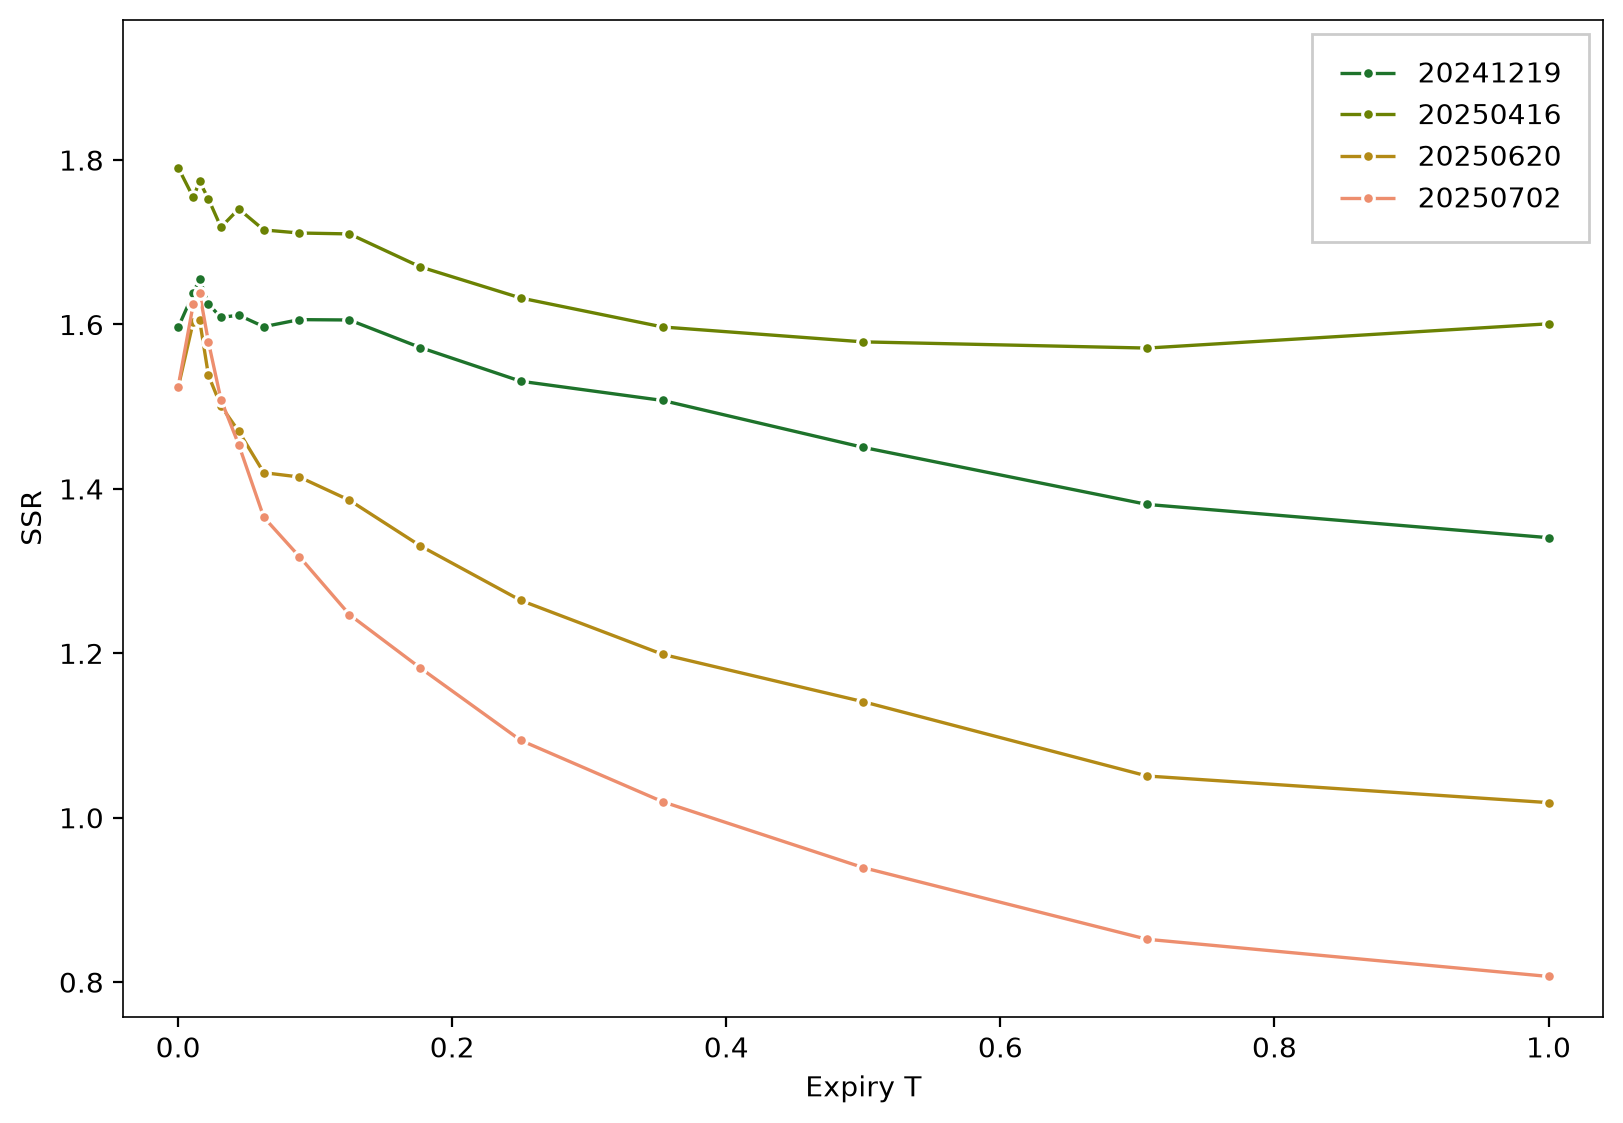

In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5), layout="constrained")
for date, color in zip(CALIB_DATES, COLORS):
    d = ssr[ssr.date == date]
    ax.plot(
        d.expiry,
        d.ssr,
        color=color,
        label=date,
        linestyle="-",
        linewidth=1.2,
        marker="o",
        markersize=4.2,
        markerfacecolor=color,
        markeredgecolor=ax.get_facecolor(),
        markeredgewidth=1.1,
        solid_capstyle="butt",
        dash_capstyle="butt",
    )
ax.set(xlabel="Expiry T", ylabel="SSR", xlim=(-0.04, 1.04))
ax.set_ylim(top=ssr.ssr.max() + 0.18)
ax.legend(loc="upper right", fancybox=False, borderpad=1)
plt.show()